# Phase 5 - Linear regression, from scratch

The model code lives in `src/models/linear.py`. This notebook opens it up and shows **how it learns**, step by step.

The whole idea in one line:

$$\text{predicted points} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_k x_k$$

The $x$'s are features (last-10 average, opponent defense...). The $w$'s are **weights** the model learns.
"Learning" means: find the weights that make the prediction errors on the training data as small as possible.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))
from src.evaluate import load_data, get_split, score
from src.models.linear import LinearRegressionScratch, Preprocessor, CORE, ALL

BLUE, ORANGE, INK, INK_2 = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": "#e8e7e2", "axes.axisbelow": True, "axes.titleweight": "bold",
    "axes.titlesize": 13, "figure.dpi": 110,
})

df = load_data()
train, valid = get_split(df, "valid")
print(f"train: {len(train):,} rows (2021-24)   valid: {len(valid):,} rows (2024-25)")

train: 74,185 rows (2021-24)   valid: 25,688 rows (2024-25)


## 1. The simplest case: one feature

Let's predict points from just **one** feature: the weighted average `PTS_EWM20`. Then the model is a straight line:
`points = w0 + w1 * EWMA`. Learning = finding the best line through the cloud of dots.

Learned line:  points = 0.52 + 0.959 x EWMA


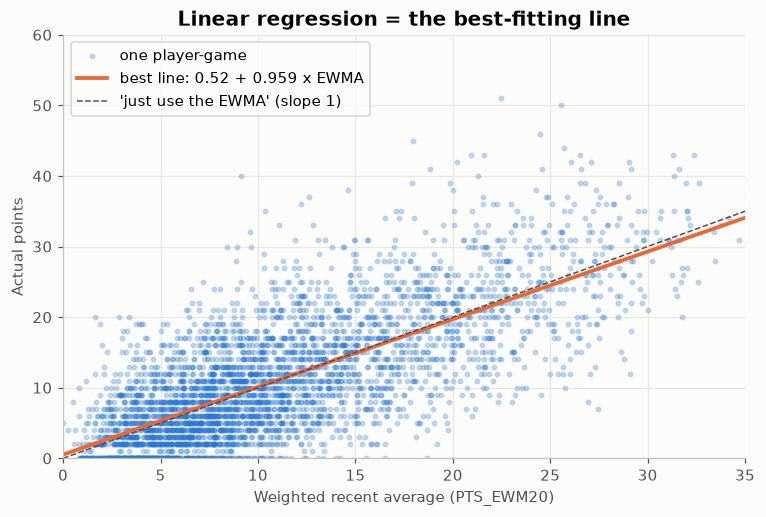

In [2]:
x = train["PTS_EWM20"].to_numpy()
y = train["PTS"].to_numpy(float)

# Normal equation by hand, for one feature:  w = (X^T X)^-1 X^T y
X = np.column_stack([np.ones(len(x)), x])        # column of 1s = the intercept w0
w = np.linalg.solve(X.T @ X, X.T @ y)
print(f"Learned line:  points = {w[0]:.2f} + {w[1]:.3f} x EWMA")

sample = train.sample(4000, random_state=0)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sample["PTS_EWM20"], sample["PTS"], s=8, alpha=0.25, color=BLUE, label="one player-game")
xs = np.linspace(0, 35, 50)
ax.plot(xs, w[0] + w[1] * xs, color=ORANGE, linewidth=2.5, label=f"best line: {w[0]:.2f} + {w[1]:.3f} x EWMA")
ax.plot(xs, xs, color=INK_2, linewidth=1, linestyle="--", label="'just use the EWMA' (slope 1)")
ax.set(xlabel="Weighted recent average (PTS_EWM20)", ylabel="Actual points", xlim=(0, 35), ylim=(0, 60),
       title="Linear regression = the best-fitting line")
ax.legend(loc="upper left")
plt.show()

**What this tells us:** the learned slope is a bit **less than 1**, plus a small intercept. In words: *"take his average,
but pull it slightly toward the middle."* High averages tend to come down a bit and low ones go up a bit -
that's **regression to the mean** (where the name "regression" originally came from!).

## 2. How "best" is measured: squared error

The normal equation finds the line with the smallest **mean squared error (MSE)**: square each miss, then average.
Squaring makes big misses count a lot more than small ones.

Our scoreboard uses **MAE** (average miss, not squared). These two don't always agree - which explains
something odd in the leaderboard:

In [3]:
one = LinearRegressionScratch(["PTS_EWM20"]).fit(train)
for name, pred in [("EWMA as-is (baseline)", valid["PTS_EWM20"]), ("Linear regression on EWMA", one.predict(valid))]:
    m = score(valid["PTS"], pred)
    print(f"{name:<28} MAE {m['MAE']:.3f}   RMSE {m['RMSE']:.3f}")

EWMA as-is (baseline)        MAE 4.658   RMSE 6.096
Linear regression on EWMA    MAE 4.673   RMSE 6.085


The regression **wins on RMSE** (what it was trained to minimize) but **loses slightly on MAE**. Lesson: a model gets good at
whatever you train it on. Points are skewed (a few huge nights), and squared error chases those big nights a little.
We'll stay with MAE as our scoreboard because it's easiest to understand: "we miss by X points on average."

## 3. Gradient descent: learning by taking small steps downhill

The normal equation jumps straight to the answer. **Gradient descent** gets there by trial and improvement:

1. Start with all weights = 0.
2. Make predictions, measure the error.
3. Compute the **gradient**: for each weight, which direction (up or down) reduces the error, and how strongly.
4. Nudge every weight a small step in that direction (step size = the **learning rate**).
5. Repeat thousands of times.

This is *exactly* how neural networks learn in Phase 9, so it's worth seeing it work here.

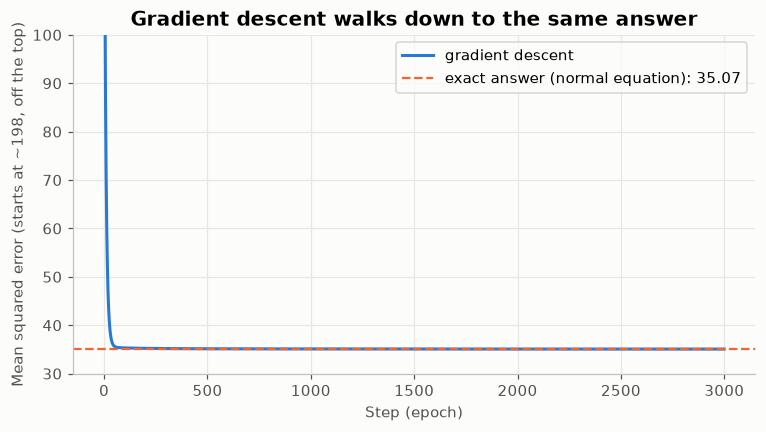

after step    0: MSE = 197.93
after step   10: MSE = 70.67
after step  100: MSE = 35.31
after step 1000: MSE = 35.10
after step 2999: MSE = 35.07


In [4]:
gd = LinearRegressionScratch(CORE, method="gd", lr=0.03, epochs=3000).fit(train)
exact = LinearRegressionScratch(CORE, method="normal").fit(train)
best_loss = np.mean((exact.predict(train) - train["PTS"]) ** 2)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gd.loss_history, color=BLUE, linewidth=2, label="gradient descent")
ax.axhline(best_loss, color=ORANGE, linestyle="--", linewidth=1.5, label=f"exact answer (normal equation): {best_loss:.2f}")
ax.set(ylim=(30, 100), xlabel="Step (epoch)", ylabel="Mean squared error (starts at ~198, off the top)",
       title="Gradient descent walks down to the same answer")
ax.legend()
plt.show()

for step in [0, 10, 100, 1000, 2999]:
    print(f"after step {step:>4}: MSE = {gd.loss_history[step]:.2f}")

**What this tells us:** the error drops fast at first (big easy improvements), then slowly creeps toward the exact answer.
After 3000 steps it's essentially the same as the formula.

Try it yourself: change `lr=0.03` to `lr=0.3` and re-run. The learning rate is too big - the steps overshoot the bottom
and the error **explodes**. Then try `lr=0.001`: too small, it barely moves. Picking the learning rate is a real skill.

## 4. What did the model learn? Reading the weights

Because every feature was **standardized** (mean 0, spread 1), each weight means:
*"how many points the prediction changes when this feature goes up by one typical amount."*

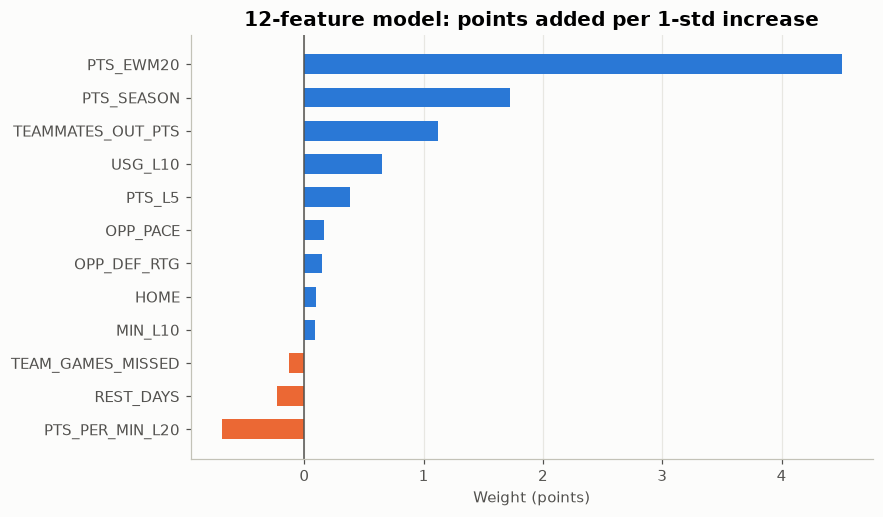

Teammates out: each 10 points of missing teammate scoring adds +0.65 pts to the prediction


In [5]:
coefs = exact.coefficients().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(coefs.index, coefs.values, color=[ORANGE if v < 0 else BLUE for v in coefs.values], height=0.6)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set(title="12-feature model: points added per 1-std increase", xlabel="Weight (points)")
ax.grid(axis="y", visible=False)
plt.show()

# Translate one weight back into real units:
std_out = exact.prep.stds["TEAMMATES_OUT_PTS"]
per_point = exact.coefficients()["TEAMMATES_OUT_PTS"] / std_out
print(f"Teammates out: each 10 points of missing teammate scoring adds {10 * per_point:+.2f} pts to the prediction")

**How to read this (carefully!):**
- The big weights go to the scoring averages, as expected.
- `TEAMMATES_OUT_PTS` gets a clearly positive weight - the Phase 2 finding holds up inside a real model.
- `REST_DAYS` is negative - the same "returning from injury" confounding we found in Phase 1.
- **Watch out for strange signs.** `PTS_PER_MIN_L20` (scoring rate) is *negative* - but obviously scoring faster doesn't
  make you score less! The scoring averages and usage rate already contain that information, and when features overlap this
  much, the model can split the credit in odd ways (a big + on one, a - on another). The *predictions* are still fine,
  but individual weights become hard to interpret. That's called **multicollinearity**.

## 5. Ridge: a penalty for big weights

Ridge regression adds `l2 x (sum of squared weights)` to the error, so the model only uses a big weight if it really
earns it. It's the standard fix for correlated features. We pick `l2` using the **validation** set.

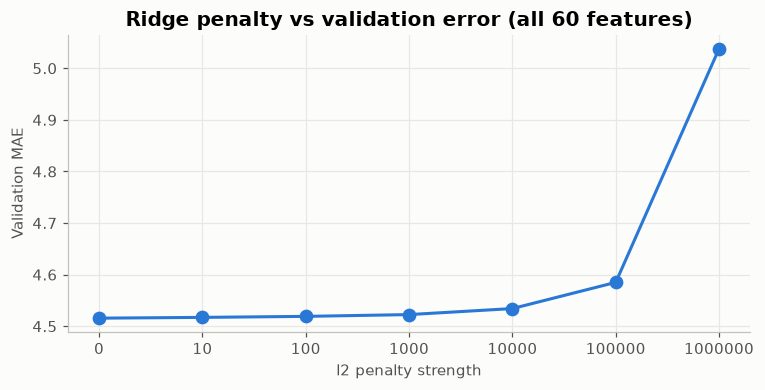

In [6]:
grid = [0, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
maes = []
for l2 in grid:
    m = LinearRegressionScratch(ALL, l2=l2).fit(train)
    maes.append(score(valid["PTS"], m.predict(valid))["MAE"])

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot([str(g) for g in grid], maes, "o-", color=BLUE, linewidth=2, markersize=8)
ax.set(title="Ridge penalty vs validation error (all 60 features)", xlabel="l2 penalty strength", ylabel="Validation MAE")
plt.show()

**What this tells us:** here, Ridge **doesn't help** - the best penalty is ~0, and big penalties make things worse.
Why? We have ~74,000 training rows and only 60 features. With that much data, the model isn't overfitting, so there's
nothing for the penalty to fix. Regularization matters most when data is small or features are many - remember this
for the neural network, where it will matter a lot.

## 6. Scoreboard

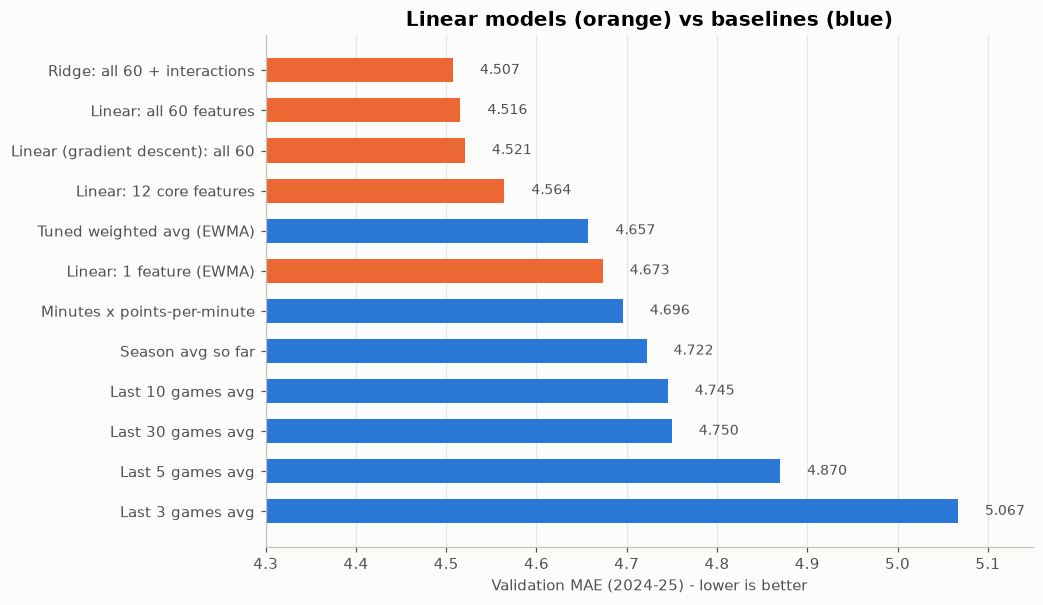

In [7]:
board = pd.read_csv("../results/leaderboard.csv")
board = board[(board["split"] == "valid") & ~board["model"].str.startswith("League")].sort_values("MAE", ascending=False)
fig, ax = plt.subplots(figsize=(9, 0.42 * len(board) + 1))
is_linear = board["model"].str.contains("Linear|Ridge")
ax.barh(board["model"], board["MAE"], color=np.where(is_linear, ORANGE, BLUE), height=0.6)
for i, m in enumerate(board["MAE"]):
    ax.text(m + 0.03, i, f"{m:.3f}", va="center", color=INK_2, fontsize=9)
ax.set(xlim=(4.3, 5.15), xlabel="Validation MAE (2024-25) - lower is better",
       title="Linear models (orange) vs baselines (blue)")
ax.grid(axis="y", visible=False)
plt.show()

*(The x-axis starts at 4.3 to make the differences visible. "League average" at 7.05 is left out - it would squash everything else.)*

## 7. Summary

| What | MAE | Lesson |
|---|---|---|
| Best baseline (EWMA) | 4.658 | The bar to beat |
| Linear, 1 feature | 4.673 | Same info as the baseline - can't beat it on MAE (it optimizes squared error) |
| Linear, 12 core features | 4.564 | Combining signals is where the gain comes from |
| Linear, all 60 features | 4.516 | More (honest) features keep helping a little |
| Gradient descent, all 60 | 4.521 | Same answer as the formula, reached by small steps |
| **Ridge + interactions** | **4.507** | Hand-made "this x that" features add a bit; the penalty itself doesn't help with this much data |

**Overall: 4.658 -> 4.507, about 3% better than the best baseline.** That's a genuine improvement for game-level noise.

**The limitation:** a linear model can only *add* effects. Real basketball has lots of *"it depends"*
(defense matters more for stars, teammates-out matters more for ball-dominant players). We had to hand-craft interaction
features for that. **Tree models (Phase 7) discover those automatically.** But first, Phase 6 asks a different question:
instead of one number, *what's the full range of outcomes?*